# MET CS555: Homework 3

Chris Davis

## Questions

The data gives the number of meals eaten that contain fish (per week) and mercury levels in head hair for 100 fishermen. Save the data to a format that can be read into R or Python. Read the data in for analysis. Use R or Python to calculate the quantities and generate the visual summaries requested below.

<em style="color:#333333">(1) To get a sense of the data, generate a scatterplot (using an appropriate window, label the axes, and title the graph). Consciously decide which variable should be on the x-axis and which should be on the y-axis. Using the scatterplot, describe the form, direction, and strength of the association between the variables. (4 points)</em>

Fish meals per week is on the x-axis (explanatory). Mercury in head hair is on the y-axis (response).

The points show a positive association. As fish meals go up, mercury tends to go up. The form looks roughly linear. The relationship is moderately strong, but there is still a fair amount of scatter around the line. See appendix, question 1.

![Fish meals and mercury](fish_mercury_scatter.png)

<em style="color:#333333">(2) Calculate the correlation coefficient. What does the correlation tell us? (2 points)</em>

The correlation is r = 0.699.

That is a moderately strong positive linear association between fish meals per week and mercury in head hair. See appendix, question 2.

<em style="color:#333333">(3) Find the equation of the least squares regression equation and write out the equation. Add the regression line to the scatterplot you generated above. (2 points)</em>

Predicted mercury (mg/g) = 1.6876 + 0.2760 × (fish meals per week).

See appendix, question 3.

![Fish meals and mercury with least-squares line](fish_mercury_regression.png)

<em style="color:#333333">(4) What is the estimate for β₀? How can we interpret this value? What is the estimate for β₁? What is the interpretation of this value? For the interpretations, you should be interpreting them in the context of this specific data set. (4 points)</em>

The estimate for β₀ is 1.6876 mg/g. That is the estimated mean mercury level for fishermen who eat 0 fish meals per week.

The estimate for β₁ is 0.2760 mg/g per fish meal. For each additional fish meal per week, the estimated mean mercury level goes up by 0.2760 mg/g. See appendix, question 4.

<em style="color:#333333">(5) Calculate the ANOVA table AND the table which gives the standard error of β₁. Formally test the hypothesis that β₁ = 0 using either the F-test or the t-test at the α = 0.05 level. Either way, present your results using the 5-step procedure, as described in the course notes.</em>

<em style="color:#333333">Within your conclusion, calculate the R-squared value and interpret this. Also, calculate (using R or Python) and interpret the 90% confidence interval for β₁. (8 points)</em>

ANOVA table:

| Source | DF | SS | MS | F |
|---|---:|---:|---:|---:|
| Regression | 1 | 309.24 | 309.24 | 93.69 |
| Residual | 98 | 323.47 | 3.30 |  |
| Total | 99 | 632.71 |  |  |


Coefficient table:

| Term | Estimate | Standard error | t | p-value |
|---|---:|---:|---:|---:|
| Intercept | 1.6876 | 0.2983 | 5.657 | < 0.0001 |
| Fish meals | 0.2760 | 0.0285 | 9.679 | < 0.0001 |


1. Null hypothesis: β₁ = 0. Alternative: β₁ ≠ 0. Alpha = 0.05.
2. t statistic for the slope, with df = 98. (The F test for the regression is equivalent here.)
3. Reject H0 if |t| > 1.984; otherwise, fail to reject H0.
4. t = 9.679. The two-sided p-value is about 6.01 × 10^-16.
5. |t| is greater than 1.984, so reject H0. There is a statistically significant linear relationship between fish meals per week and mean mercury level.

R-squared = 0.489. About 48.9% of the variation in mercury is explained by the linear relationship with fish meals per week.

90% CI for β₁ = (0.2286, 0.3233).

We are 90% confident that each additional fish meal per week is associated with an increase of between 0.2286 and 0.3233 mg/g in mean mercury. See appendix, question 5.

## Appendix: Code

In [ ]:
# Setup

%pip install numpy pandas matplotlib scipy

In [4]:
# Setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline


In [5]:
# Read the data

fish = pd.read_csv("data.csv")
print("rows read =", len(fish))
print(fish.head())


rows read = 100
   fish_meals_per_week  mercury_mg_g
0                   14         4.484
1                    7         4.789
2                    5         3.856
3                    8         4.888
4                   21        10.849


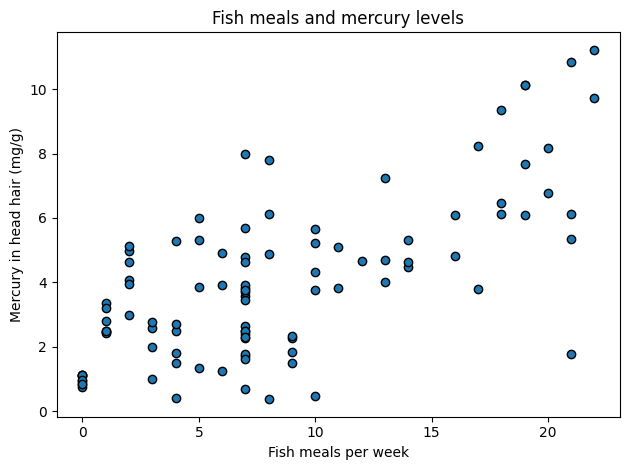

In [6]:
# Question 1

x = fish["fish_meals_per_week"]
y = fish["mercury_mg_g"]

plt.scatter(x, y, edgecolor="black")
plt.xlabel("Fish meals per week")
plt.ylabel("Mercury in head hair (mg/g)")
plt.title("Fish meals and mercury levels")
plt.tight_layout()
plt.savefig("fish_mercury_scatter.png")
plt.show()


In [7]:
# Question 2

r = x.corr(y)
print("correlation =", round(r, 3))


correlation = 0.699


intercept = 1.6876
slope = 0.2760
equation: predicted mercury = 1.6876 + 0.2760 * fish meals


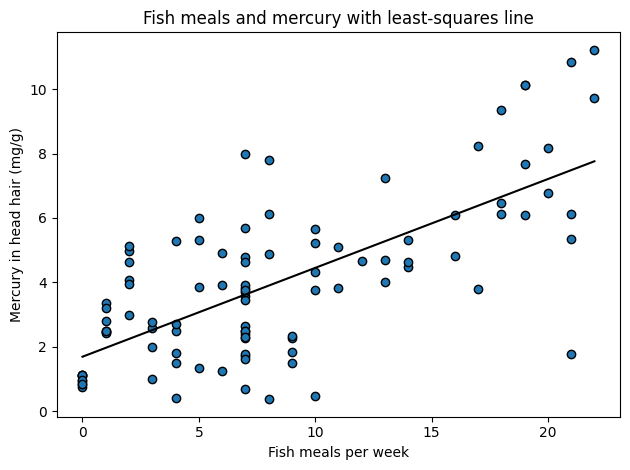

In [8]:
# Question 3

slope, intercept, r_value, p_value, se_slope = stats.linregress(x, y)

print("intercept =", f"{intercept:.4f}")
print("slope =", f"{slope:.4f}")
print("equation: predicted mercury =", f"{intercept:.4f} + {slope:.4f} * fish meals")

xx = np.linspace(x.min(), x.max(), 100)
plt.scatter(x, y, edgecolor="black")
plt.plot(xx, intercept + slope * xx, color="black")
plt.xlabel("Fish meals per week")
plt.ylabel("Mercury in head hair (mg/g)")
plt.title("Fish meals and mercury with least-squares line")
plt.tight_layout()
plt.savefig("fish_mercury_regression.png")
plt.show()


In [9]:
# Question 4

print("b0 (intercept) =", f"{intercept:.4f}")
print("b1 (slope) =", f"{slope:.4f}")


b0 (intercept) = 1.6876
b1 (slope) = 0.2760


In [10]:
# Question 5

n = len(fish)
yhat = intercept + slope * x
resid = y - yhat
sse = float(np.sum(resid ** 2))
sst = float(np.sum((y - y.mean()) ** 2))
ssr = sst - sse
mse = sse / (n - 2)
msr = ssr / 1
f_stat = msr / mse
df_resid = n - 2

xbar = float(x.mean())
sxx = float(np.sum((x - xbar) ** 2))
s = np.sqrt(mse)
se_intercept = s * np.sqrt(1 / n + xbar ** 2 / sxx)
t_slope = slope / se_slope
t_intercept = intercept / se_intercept
p_slope = 2 * stats.t.sf(abs(t_slope), df_resid)
p_intercept = 2 * stats.t.sf(abs(t_intercept), df_resid)
t_crit = stats.t.ppf(0.975, df_resid)
t_90 = stats.t.ppf(0.95, df_resid)
ci_low = slope - t_90 * se_slope
ci_high = slope + t_90 * se_slope
rsq = ssr / sst

anova = pd.DataFrame({
    "DF": [1, df_resid, n - 1],
    "SS": [ssr, sse, sst],
    "MS": [msr, mse, np.nan],
    "F": [f_stat, np.nan, np.nan],
}, index=["Regression", "Residual", "Total"]).round(2)
print(anova.to_string())
print()

coef = pd.DataFrame({
    "Estimate": [intercept, slope],
    "SE": [se_intercept, se_slope],
    "t": [t_intercept, t_slope],
    "p-value": [p_intercept, p_slope],
}, index=["Intercept", "Fish meals"]).round(4)
print(coef.to_string())
print()
print("critical t =", round(t_crit, 3))
print("R-squared =", round(rsq, 3))
print("90% CI for slope =", round(ci_low, 4), "to", round(ci_high, 4))


            DF      SS      MS      F
Regression   1  309.24  309.24  93.69
Residual    98  323.47    3.30    NaN
Total       99  632.71     NaN    NaN

            Estimate      SE       t  p-value
Intercept     1.6876  0.2983  5.6570      0.0
Fish meals    0.2760  0.0285  9.6793      0.0

critical t = 1.984
R-squared = 0.489
90% CI for slope = 0.2286 to 0.3233
